# 1. Импорты

In [186]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 2. Параметры и классы

In [187]:
path_to_folder = './data'
IMAGE_SIZE = 32
K_VALUES = [1, 2, 3, 5, 7, 9, 11, 15]
RANDOM_STATE = 42

name_folders = [x[0].split('\\')[-1] for x in os.walk(path_to_folder)][1:]
NUM_CLASSES = len(name_folders)
print(f"Classes: {NUM_CLASSES}")
print(name_folders)

Classes: 22
['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '1', '9', 'h', 't', 'times', 'w', 'X', 'y']


# 3. Генератор произвольной последовательности

In [188]:
ALLOWED_CHARS = list('0123456789') + list('+-*()') + list('htwy')

def generate_sequence():
    tpl = random.choice([
        "{d}{op}{d}",
        "({d}{op}{d})",
        "{v}{op}{d}",
        "({v}{op}{d}){op}{d}",
        "{d}{op}{v}{op}{d}",
    ])
    return tpl.format(
        d=random.choice('123456789'),
        v=random.choice('htwy'),
        op=random.choice('+-*'),
    )

for _ in range(5):
    print(generate_sequence())

w+8
7+7
(w+2)+2
6+y+6
y+4


# 4. Рендеринг строки в изображение

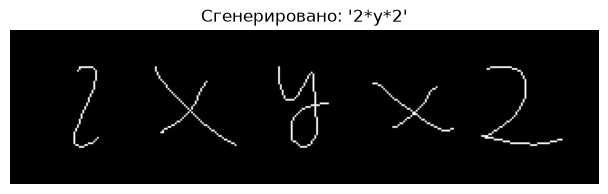

In [200]:
def render_sequence(expr, img_size=IMAGE_SIZE):
    images = []
    for char in expr:
        actual_char = 'times' if char == '*' else char
        folder = os.path.join(path_to_folder, actual_char)
        if not os.path.exists(folder):
            continue
        
        files = os.listdir(folder)
        if not files:
            continue

        img = cv2.imread(os.path.join(folder, random.choice(files)), cv2.IMREAD_GRAYSCALE)
        img = cv2.bitwise_not(img)
        
        if len(images) > 0:
            images.append(np.zeros((img.shape[0], 15), dtype=np.uint8))
            
        images.append(img)

    if not images:
        return None
    result = np.hstack(images)
    return cv2.copyMakeBorder(result, 20, 20, 20, 20, cv2.BORDER_CONSTANT, value=0)

demo_expr = generate_sequence()
demo_img = render_sequence(demo_expr)

plt.figure(figsize=(8, 2))
plt.imshow(demo_img, cmap='gray')
plt.title(f"Сгенерировано: {demo_expr!r}")
plt.axis('off')
plt.show()

# 5. Загрузка датасета

In [190]:
def load_dataset():
    X, y = [], []
    for class_idx, cls_name in enumerate(name_folders):
        folder = os.path.join(path_to_folder, cls_name)
        if not os.path.isdir(folder):
            continue
        for name in os.listdir(folder):
            img = cv2.imread(os.path.join(folder, name), cv2.IMREAD_GRAYSCALE)
            if img is None:
                continue
            img = cv2.bitwise_not(img)
            img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))
            X.append(img.flatten().astype(np.float32) / 255.0)
            y.append(class_idx)
    return np.array(X), np.array(y)

X, y = load_dataset()
print("X:", X.shape, "y:", y.shape)

X: (251811, 1024) y: (251811,)


# 6. Train/test split

In [191]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, shuffle=True, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (176267, 1024) Test: (75544, 1024)


# 7. Подбор k

k =  1 | accuracy = 0.8656
k =  2 | accuracy = 0.8229
k =  3 | accuracy = 0.8009
k =  5 | accuracy = 0.7233
k =  7 | accuracy = 0.6944
k =  9 | accuracy = 0.6722
k = 11 | accuracy = 0.6533
k = 15 | accuracy = 0.6137

Оптимальное k = 1, accuracy = 0.8656


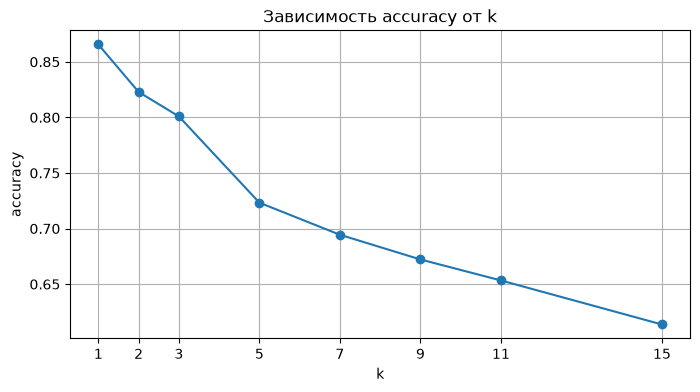

In [192]:
accuracies = []
for k in K_VALUES:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    accuracies.append(acc)
    print(f"k = {k:2d} | accuracy = {acc:.4f}")

best_k = K_VALUES[int(np.argmax(accuracies))]
print(f"\nОптимальное k = {best_k}, accuracy = {max(accuracies):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(K_VALUES, accuracies, marker='o')
plt.xlabel('k'); plt.ylabel('accuracy')
plt.title('Зависимость accuracy от k')
plt.grid(True); plt.xticks(K_VALUES)
plt.show()

# 8. Финальная модель и отчёт

In [193]:
classifier = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=name_folders, digits=3, zero_division=0))

Accuracy: 0.8656

[[ 4270     0     0     0     0     0    18     0     0     0     0     0
      0     0     0     0     0     0     0     0     0     0]
 [    0  4289     0    15     0     0     0     0     0     0     0     0
      0     0     3     0     0     0     0     0     0     0]
 [    9     3  7372     3    70     0    31     0     0     0     0     0
      0     0    38     0     0     8     0     0     0     0]
 [    5     6     0   510     0     0    37     0     0     0     0     0
      0     0    14     0     0     0     0     0     0     0]
 [    0     0     0     0 10198     0     1     0     0     0     0     0
      0     0     0     0     0     0     0     0     0     0]
 [    8     0     0     3     0  2054     0     0     3     0     0     3
      0     0     0     0     0     0     0     0     3     0]
 [    2     0     0     1     0     0  3451     0     0     0     0     0
      0     0  4502     0     0     0     0     0     0     0]
 [   29    24     0    

# 9. Сегментация

In [194]:
def segment_sequence(img):
    _, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
    
    kernel = np.ones((2, 2), np.uint8)
    thresh_dilated = cv2.dilate(thresh, kernel, iterations=1)
    
    contours, _ = cv2.findContours(thresh_dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    bboxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w * h > 100:
            bboxes.append((x, y, w, h))
            
    bboxes.sort(key=lambda b: b[0])
    return bboxes

# 10. Распознавание последовательности

In [195]:
def recognize_sequence(expr=None, verbose=True):
    if expr is None:
        expr = generate_sequence()

    test_img = render_sequence(expr)
    if test_img is None:
        return expr, ""

    bboxes = segment_sequence(test_img)
    recognized = ""
    vis = cv2.cvtColor(test_img, cv2.COLOR_GRAY2RGB)
    debug_rois = []

    for (x, y_, w, h) in bboxes:
        roi_orig = test_img[y_:y_+h, x:x+w]
        
        points = cv2.findNonZero((roi_orig > 127).astype(np.uint8))
        if points is not None:
            rx, ry, rw, rh = cv2.boundingRect(points)
            roi_tight = roi_orig[ry:ry+rh, rx:rx+rw]
        else:
            roi_tight = roi_orig 
            
        side = max(rw, rh)
        pad_y = (side - rh) // 2
        pad_x = (side - rw) // 2
        
        roi_sq = cv2.copyMakeBorder(roi_tight, pad_y, side-rh-pad_y, pad_x, side-rw-pad_x, 
                                    cv2.BORDER_CONSTANT, value=0)
        
        roi_resized = cv2.resize(roi_sq, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)

        vec = roi_resized.flatten().reshape(1, -1).astype(np.float32) / 255.0
        idx = int(classifier.predict(vec)[0])
        pred_char = name_folders[idx]
        display_char = '*' if pred_char == 'times' else pred_char
        recognized += display_char
        
        debug_rois.append(roi_resized)
        
        cv2.rectangle(vis, (x, y_), (x+w, y_+h), (0, 200, 0), 1)
        cv2.putText(vis, display_char, (x, max(y_-4, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

    if verbose:
        plt.figure(figsize=(max(8, len(expr)*1.2), 3))
        plt.imshow(vis); plt.axis('off'); plt.title("Распознанная строка"); plt.show()
        
        if debug_rois:
            fig, axes = plt.subplots(1, len(debug_rois), figsize=(len(debug_rois)*2, 2))
            if len(debug_rois) == 1: axes = [axes]
            for i, (ax, r) in enumerate(zip(axes, debug_rois)):
                ax.imshow(r, cmap='gray')
                ax.set_title(f"В KNN: {r.shape}")
                ax.axis('off')
            plt.show()
            
        print(f"Ожидалось : {expr!r}")
        print(f"Распознано: {recognized!r}")
        print(f"Совпало   : {expr == recognized}")

    return expr, recognized

# 11. Демонстрация

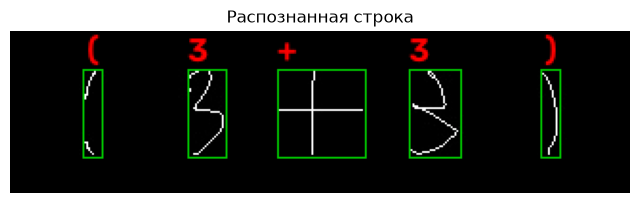

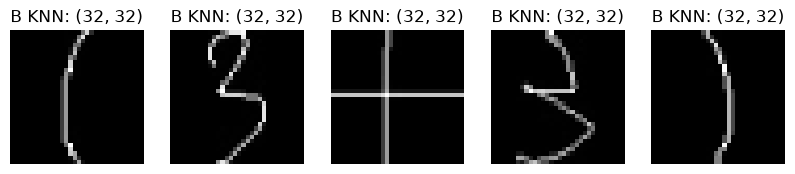

Ожидалось : '(3+3)'
Распознано: '(3+3)'
Совпало   : True
----------------------------------------


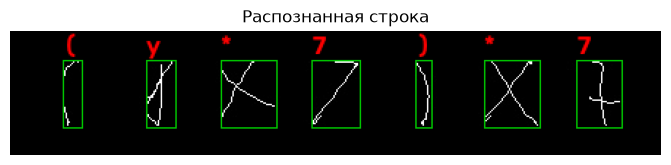

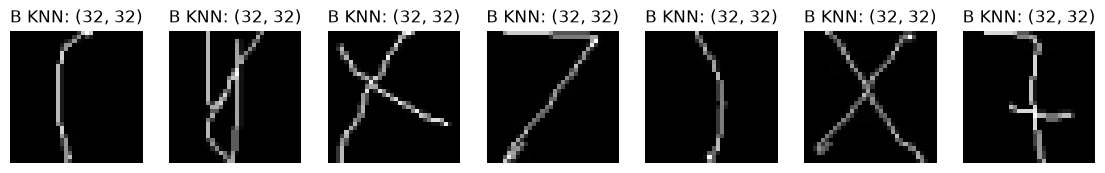

Ожидалось : '(y*7)*7'
Распознано: '(y*7)*7'
Совпало   : True
----------------------------------------


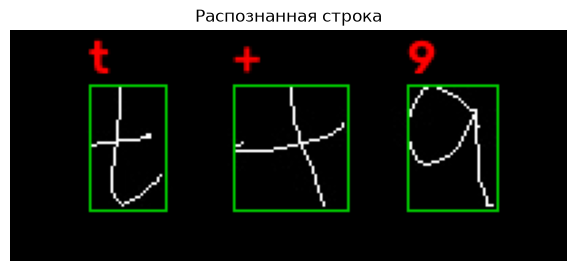

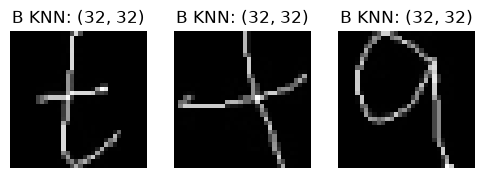

Ожидалось : 't+9'
Распознано: 't+9'
Совпало   : True
----------------------------------------


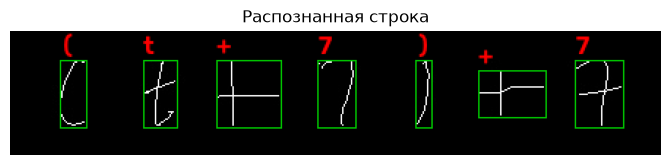

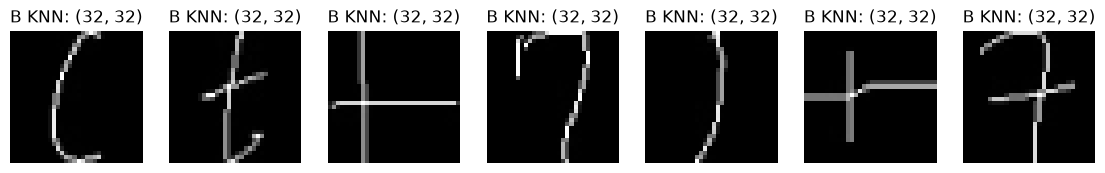

Ожидалось : '(t+7)+7'
Распознано: '(t+7)+7'
Совпало   : True
----------------------------------------


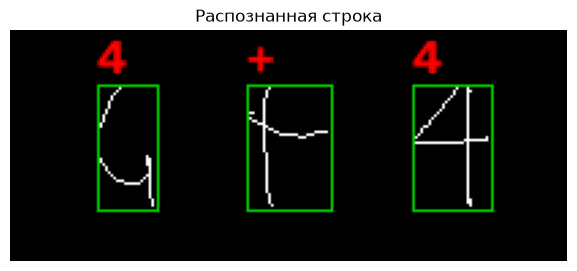

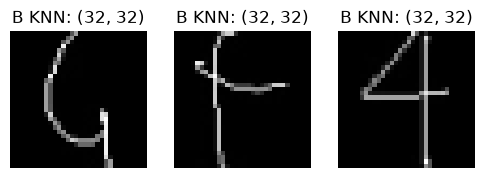

Ожидалось : '4+4'
Распознано: '4+4'
Совпало   : True
----------------------------------------


In [198]:
for _ in range(5):
    recognize_sequence()
    print('-' * 40)

# 12. Метрика на N сгенерированных выражениях

In [199]:
N = 100
correct = 0
for _ in range(N):
    ground, rec = recognize_sequence(verbose=False)
    correct += int(ground == rec)

print(f"Точное совпадение выражений: {correct}/{N} = {correct / N:.3f}")

Точное совпадение выражений: 83/100 = 0.830
